# ÉquiAlgo : rapport d'audit

Source de ce carnet : `audit_rapport.py`. Le carnet est généré et exécuté par
`python build.py` ; il ne se modifie pas à la main. Chaque nombre du rapport est la
sortie d'une cellule : le texte commente les tableaux, il ne les recopie pas.

## 0. Résumé

- Le comité historique accordait nettement moins de bourses aux régions éloignées
  qu'aux grands centres. La différence de cote R entre les deux groupes n'explique
  presque rien de cet écart.
- Le comité se décrit très bien par quatre éléments : la cote R, les heures travaillées,
  le revenu familial (les revenus élevés étaient favorisés) et une **pénalité constante**
  appliquée aux régions éloignées. Cette pénalité explique à elle seule la plus grande
  part de l'écart ; la préférence pour le revenu explique presque tout le reste.
- Le modèle en production a appris ces décisions, pénalité comprise. Retirer la région de
  ses entrées ne change presque rien : la distance, le code postal, les heures et le
  revenu la redonnent.
- La correction retenue réapprend les poids du comité, puis retire la pénalité et la
  préférence pour le revenu. Elle classe les candidats selon la cote R et les heures
  travaillées, sans lire la région, et les deux groupes obtiennent alors le même taux
  d'octroi dans le budget.

In [1]:
import warnings

warnings.filterwarnings("ignore")

from IPython.display import display

from equialgo import audit, pitch
from equialgo.data import REGION, load_candidates, load_history

history = load_history()
candidates = load_candidates()
test, baseline_heldout, baseline = audit.baseline_decisions(history, candidates)
retained = audit.retained_decisions(candidates)
display(audit.summary(history, candidates, baseline, retained))

,valeur
"Taux d'octroi du comité, grands centres",0.484
"Taux d'octroi du comité, régions éloignées",0.273
"Pénalité régionale, en points de cote R",-1.400
Taux des régions éloignées sans la pénalité,0.429
Écart de parité du modèle en production (4 000 candidats),0.190
Écart de parité du modèle corrigé (4 000 candidats),0.000
Taux d'octroi du modèle corrigé (budget : 36 % à 44 %),0.400


## 1. Données et groupes

Deux fichiers. Le premier contient les demandes passées et la décision que le comité a
prise pour chacune (`decision_octroi`). Le second contient les nouveaux candidats, sans
décision : c'est sur eux que la correction est évaluée.

`decision_octroi` enregistre **ce que le comité a fait**, pas ce qu'il aurait dû faire.
Tout indicateur calculé contre cette colonne mesure la fidélité au comité, et le comité
est précisément ce qu'on audite.

Les cinq régions sont regroupées en deux blocs, comme dans le carnet de départ : les
grands centres (Montréal, Capitale-Nationale) et les régions éloignées
(Bas-Saint-Laurent, Côte-Nord, Gaspésie–Îles-de-la-Madeleine).

In [2]:
display(audit.file_overview(history, candidates))
display(audit.group_profiles(history))

,lignes,part grands centres,part régions éloignées,taux d'octroi du comité
donnees_demandes.csv (historique),10000.0,0.600,0.400,0.399
candidats_evaluation.csv (à évaluer),4000.0,0.593,0.407,NaN


groupe,Centre,Eloignee
cote R moyenne,27.99,27.33
revenu médian,69175.50,51561.50
heures de travail,8.97,13.02
distance médiane (km),17.00,204.50
première génération,0.26,0.44
taux d'octroi du comité,0.48,0.27


Les deux groupes n'ont pas le même profil : les candidats des régions éloignées ont une
cote R un peu plus basse, un revenu familial plus faible, travaillent davantage pendant
leurs études, habitent loin du campus et sont plus souvent les premiers de leur famille à
l'université. Ces différences comptent pour la suite : toute colonne qui distingue les
groupes peut servir de substitut à la région.

## 2. Mesure du biais

### L'écart brut

Le comité n'a pas accordé les bourses au même taux dans les deux groupes, ni dans les
cinq régions. L'intervalle est obtenu par rééchantillonnage ; la dernière colonne traduit
l'écart en nombre de bourses sur les demandes historiques des régions éloignées.

,écart de taux d'octroi (Centre - Éloignée),IC 95 % bas,IC 95 % haut,bourses en moins pour les régions éloignées
0,0.211,0.193,0.232,843


,demandes,taux_octroi,cote_r_moyenne
groupe,,,
Centre,6000,0.484,27.987
Eloignee,4000,0.273,27.327


,demandes,taux_octroi,cote_r_moyenne
region_administrative,,,
Capitale-Nationale,1999,0.484,27.984
Montreal,4001,0.483,27.988
Gaspesie-Iles-de-la-Madeleine,1529,0.284,27.354
Bas-Saint-Laurent,1293,0.269,27.296
Cote-Nord,1178,0.263,27.325


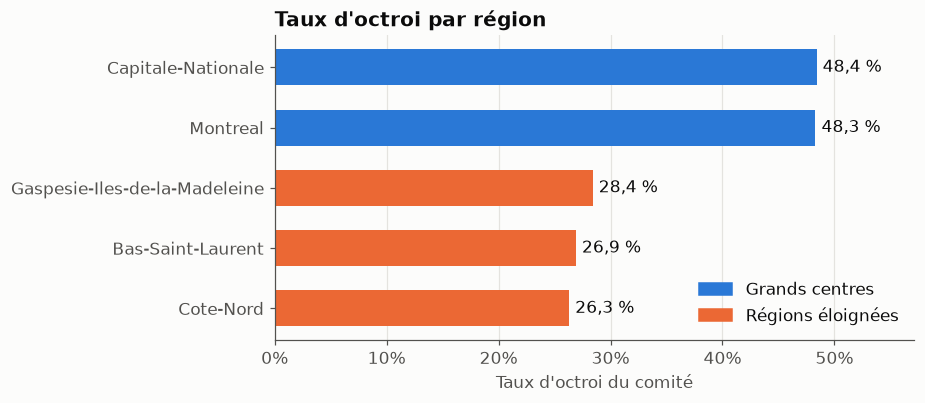

In [3]:
display(audit.raw_gap(history))
display(audit.grant_rate_table(history))
display(audit.grant_rate_table(history, by=REGION))
audit.fig_grant_rate_by_region(history)

Les trois régions éloignées sont traitées de la même façon, et les deux grands centres
aussi : l'écart passe entre les deux blocs, pas entre les régions d'un même bloc.

### À cote R égale

L'écart de cote R entre les groupes n'explique pas l'écart de taux : dans chaque tranche
de cote R, le taux d'octroi reste plus bas dans les régions éloignées.

,taux Centre,taux Eloignee,n Centre,n Eloignee,écart
cote R,,,,,
< 24,0.002,0.000,533,534,0.002
24–26,0.028,0.008,995,754,0.020
26–28,0.241,0.067,1489,1063,0.174
28–30,0.704,0.407,1443,912,0.297
30–32,0.959,0.825,990,514,0.134
≥ 32,0.998,0.987,550,223,0.012


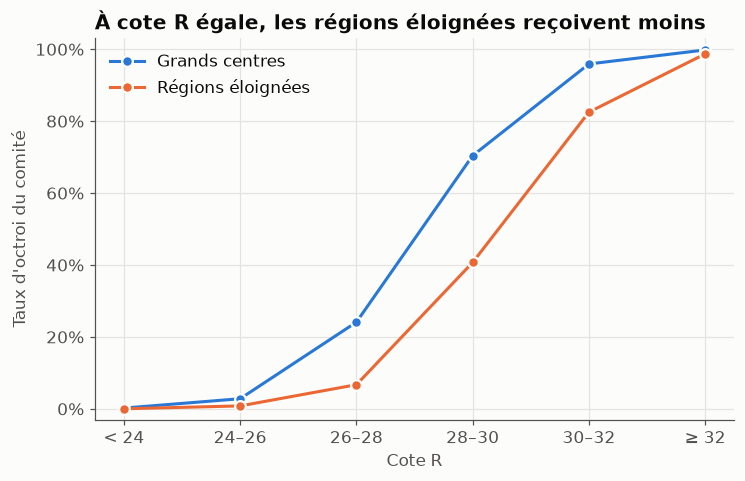

In [4]:
display(audit.grant_rate_by_r_band(history))
audit.fig_grant_rate_by_r_band(history)

### En tenant compte de tout ce que le comité regardait

Un modèle logistique de la décision du comité, avec la cote R, le revenu, les heures
travaillées et le groupe. La dernière colonne exprime chaque poids en points de cote R,
ce qui rend les termes comparables entre eux.

In [5]:
display(audit.committee_table(history))

,coefficient,erreur type,z,en points de cote R
Cote R (1 point),1.384,0.030,45.831,1.000
Revenu familial (log),1.781,0.091,19.551,1.287
Heures de travail (1 h),0.201,0.012,17.390,0.145
Région éloignée,-1.942,0.096,-20.131,-1.403


À dossier égal sur les trois autres éléments, appartenir à une région éloignée coûte
l'équivalent d'une baisse sensible de cote R (dernière colonne). Le tableau suivant vérifie que rien d'autre
n'entre dans la décision : ni la première génération, ni le programme, ni la région à
l'intérieur d'un groupe, et la pénalité ne varie pas avec la cote R. Une valeur p élevée
signifie que le terme n'apporte rien.

In [6]:
display(audit.ignored_columns(history))

,termes ajoutés,valeur p
Première génération,1.0,0.488
Programme d'études,4.0,0.978
Région à l'intérieur du groupe,3.0,0.751
Cote R x groupe (pénalité variable),1.0,0.506


## 3. D'où vient l'écart

On rejoue les décisions pour les candidats des régions éloignées avec le modèle du
comité, en retirant d'abord la pénalité, puis aussi la préférence pour le revenu.

,pénalité en points de cote R,IC 95 % bas,IC 95 % haut
0,-1.4,-1.54,-1.27


,taux d'octroi,IC 95 % bas,IC 95 % haut,bourses (sur les demandes des régions éloignées)
"Régions éloignées, décisions du comité",0.273,0.258,0.285,1092.0
… sans la pénalité régionale,0.429,0.411,0.444,1714.0
… sans la pénalité ni la préférence pour le revenu,0.478,0.461,0.494,1912.0
"Grands centres, décisions du comité",0.484,0.473,0.498,NaN


,points de taux d'octroi,part de l'écart
Pénalité régionale,15.6,0.739
Préférence pour le revenu élevé,4.9,0.232
"Reste (cote R, heures travaillées)",0.6,0.028
Écart total,21.1,1.000


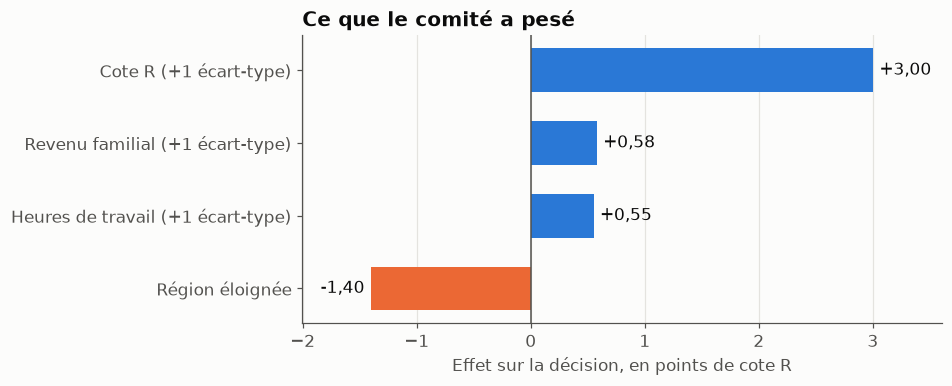

In [7]:
scenarios, penalty = audit.penalty_scenarios(history)
display(penalty)
display(scenarios)
display(audit.gap_decomposition(history))
audit.fig_committee_weights(history)

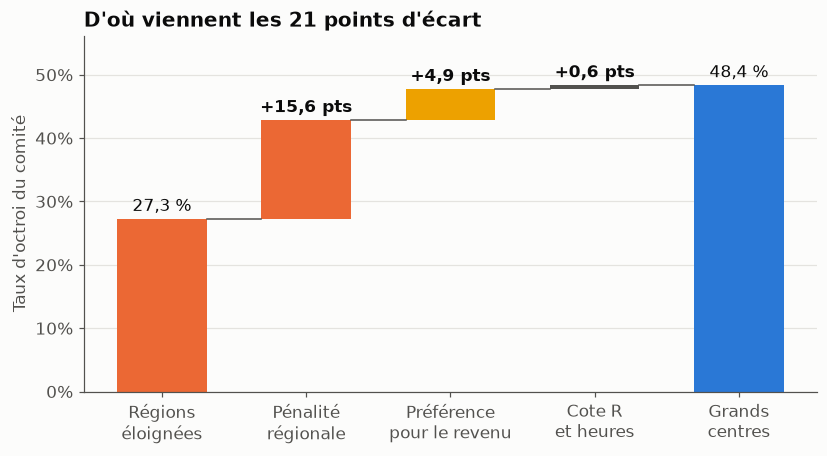

In [8]:
pitch.fig_decomposition(history)

Trois constats.

1. **La pénalité régionale** est la cause principale de l'écart. Elle est constante :
   la même pour les trois régions éloignées, à toute cote R et à tout revenu.
2. **La préférence pour le revenu** est un second biais, indirect : le comité favorisait
   les revenus élevés, et les familles des régions éloignées ont des revenus plus bas.
   Pour une aide financière, récompenser le revenu élevé est difficile à défendre ;
   c'est une décision que l'institution doit prendre explicitement (voir
   `gouvernance.md`).
3. **La cote R n'explique presque rien.** Le comité récompensait aussi les heures
   travaillées, et les candidats des régions éloignées travaillent davantage : cet
   avantage compense à peu près leur cote R légèrement plus basse. Une fois la pénalité
   et le revenu retirés, les deux groupes obtiennent presque le même taux.

## 4. Variables proxys

### Quelles colonnes trahissent la région ?

Pour chaque colonne, on mesure à quel point elle permet de deviner le groupe (AUC en
validation croisée : 0,5 signifie aucune information, 1 une prédiction parfaite).

,AUC pour deviner le groupe
Toutes les colonnes sauf la région,1.000
Code postal (3 car.),1.000
Distance au campus,0.998
"Sans région, code postal ni distance",0.854
Heures de travail,0.805
Revenu familial,0.692
Première génération,0.585
Cote R,0.561
Programme d'études,0.549


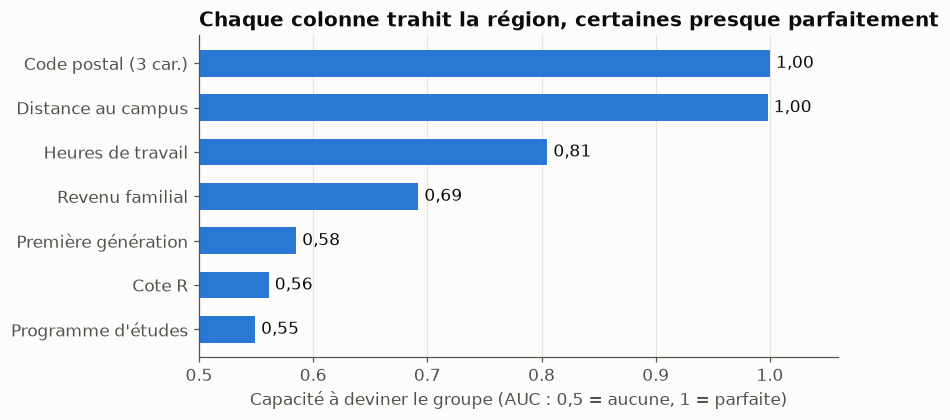

In [9]:
display(audit.proxy_table(history))
audit.fig_proxies(history)

Le code postal et la distance au campus donnent la région presque à coup sûr. Même sans
eux, les heures travaillées et le revenu suffisent à la deviner bien mieux qu'au hasard.

### Retirer des colonnes ne suffit pas

Le modèle en production est réentraîné avec de moins en moins de colonnes, puis mesuré
sur les demandes historiques mises de côté.

In [10]:
display(audit.column_removal_table(history))

,écart de parité,accord avec le comité
Toutes les colonnes (modèle en production),0.188,0.881
Sans la région,0.180,0.884
Sans la région ni le code postal,0.173,0.879
"Cote R, revenu et heures seulement",0.102,0.873
Cote R et heures seulement,0.055,0.853


Sans la région ni le code postal, l'écart bouge à peine. Il ne baisse franchement que
lorsqu'on retire aussi la distance, puis le revenu, et il en reste encore avec la cote R
et les heures seules. La raison est dans le tableau suivant.

### Le mécanisme : un proxy absorbe la pénalité

,"poids d'une heure, en points de cote R",erreur type
Comité ajusté avec le groupe,0.145,0.008
Groupe retiré du modèle,0.059,0.007
Groupe et revenu retirés,0.024,0.007


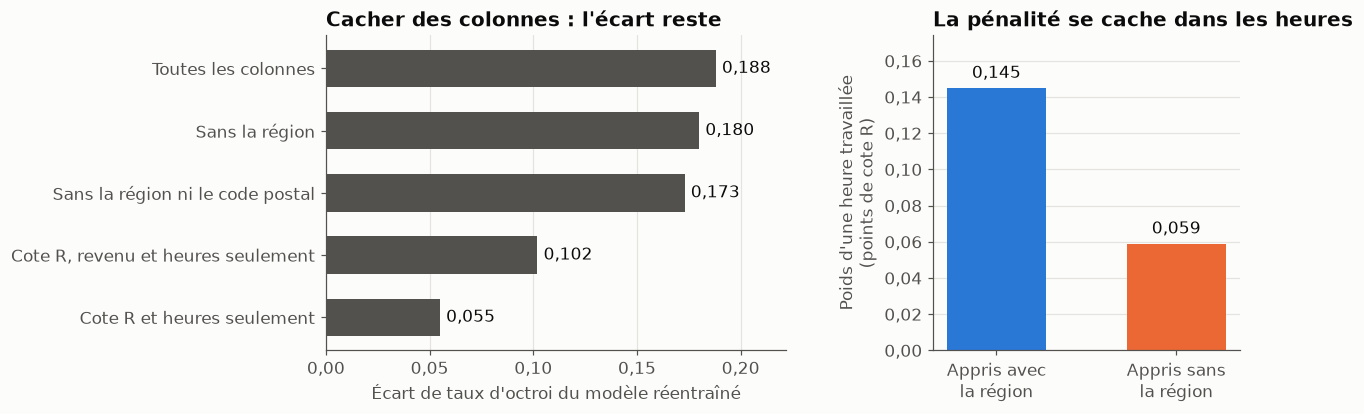

In [11]:
display(audit.hours_weight_table(history))
pitch.fig_without_region(history)

Quand le modèle voit le groupe, il attribue la pénalité au groupe et donne aux heures
travaillées leur vrai poids. Quand on lui cache le groupe, il ne peut plus expliquer les
refus des régions éloignées que par ce qui les distingue : comme leurs candidats
travaillent davantage, il apprend que les heures comptent moins. La pénalité n'a pas
disparu, elle s'est déplacée dans le poids d'une colonne qui a l'air neutre.

D'où la méthode de correction : **ajuster avec la région pour isoler la pénalité, puis
la retirer**, plutôt que cacher la région en espérant que le biais parte avec elle.

## 5. Audit du modèle en production

Le modèle en production (forêt aléatoire sur toutes les colonnes) est mesuré sur les
demandes historiques mises de côté, contre les décisions du comité.

,Centre,Eloignee,écart (Centre - Éloignée)
taux d'octroi du comité,0.484,0.277,0.207
taux d'octroi du modèle,0.459,0.271,0.188
accord avec le comité,0.878,0.887,-0.009
vrais positifs (TPR),0.847,0.785,0.063
faux positifs (FPR),0.094,0.074,0.019


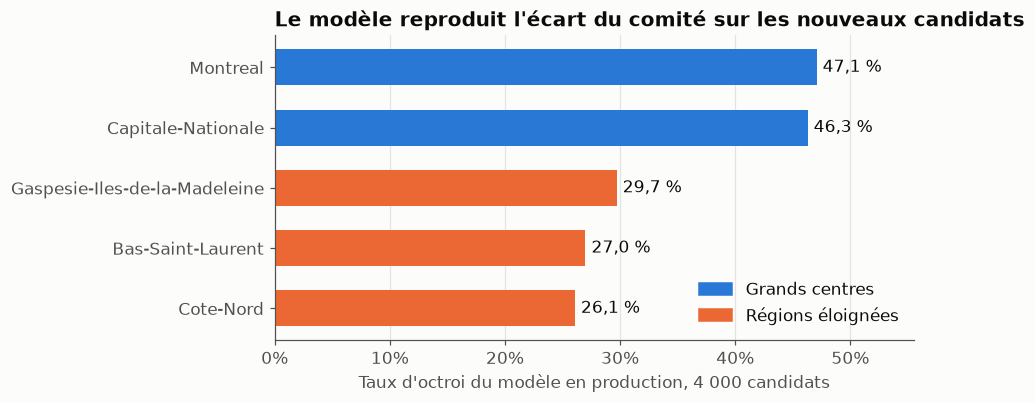

In [12]:
display(audit.production_audit(test, baseline_heldout))
audit.fig_baseline_by_region(candidates, baseline)

Le modèle reproduit le comité, écart compris, sans l'amplifier : son écart de taux
d'octroi est proche de celui du comité sur les mêmes dossiers, et il le reporte sur les
nouveaux candidats.

Son exactitude élevée ne dit rien de son équité. Elle mesure l'accord avec des décisions
biaisées : un modèle parfaitement exact reproduirait parfaitement la pénalité. De même,
ses taux de vrais positifs par groupe sont proches l'un de l'autre, parce que le
« positif » de référence est la décision du comité, qui contient déjà la pénalité.

## 6. Choix des métriques d'équité

### Pourquoi l'égalité des chances, et contre quel étalon

La parité démographique demande le même taux d'octroi dans les deux groupes. L'égalité
des chances demande que, parmi les candidats **qui méritent** la bourse, les deux groupes
aient la même chance de l'obtenir. Nous défendons la seconde : une bourse au mérite doit
traiter de la même façon deux candidats de même mérite, et non garantir un quota.

Tout dépend alors de ce qu'on appelle « mériter ». Mesuré contre les décisions du comité,
l'écart d'égalité des chances du modèle en production paraît faible ; mesuré contre un
étalon indépendant, il est plusieurs fois plus grand.

In [13]:
display(audit.committee_label_gap(test, baseline_heldout))

,TPR grands centres,TPR régions éloignées,écart mesuré contre le comité,écart publié contre l'étalon
0,0.847,0.785,0.063,0.27


L'étalon du jury n'est pas publié. Nous avons donc formulé plusieurs définitions
plausibles du mérite et mesuré les modèles contre chacune (méthode et élimination des
autres définitions : `analysis/FINDINGS.md`, blocs 8 et 9).

In [14]:
display(audit.standards_table(candidates, baseline, retained))

,"méritants, grands centres","méritants, régions éloignées","écart d'égalité des chances, production","écart d'égalité des chances, modèle corrigé"
Mérite seul (cote R),0.428,0.359,0.225,-0.080
Comité sans pénalité régionale,0.422,0.368,0.230,-0.055
Cote R + heures travaillées,0.400,0.400,0.296,0.000
Cote R + 1 pt première génération,0.419,0.372,0.223,-0.038
Cote R classée dans chaque groupe,0.400,0.400,0.306,0.004


Deux lectures de ce tableau.

- **Parité et égalité des chances ne coïncident que si les deux groupes comptent la même
  part de méritants.** Avec la cote R seule, les grands centres en comptent davantage :
  on ne peut alors pas satisfaire les deux critères à la fois. Avec la cote R et les
  heures travaillées, les deux groupes en comptent autant, et le même modèle satisfait
  les deux.
- Le modèle corrigé réduit fortement l'écart du modèle en production sous chacune des
  définitions, pas seulement sous celle qu'il incarne. Un écart négatif signifie que les
  régions éloignées sont alors légèrement favorisées.

La définition « cote R et heures travaillées » est celle que nous retenons : c'est ce que
le comité lui-même valorisait une fois ses deux biais retirés, et c'est celle qui
s'accorde le mieux avec les retours du correcteur automatique.

## 7. Sous-groupes

La correction ne doit pas déplacer le préjudice vers un autre sous-groupe. Taux d'octroi
sur les nouveaux candidats, avant (modèle en production) et après (modèle corrigé).

candidats  \
sous-groupe         valeur                        groupe                
Première génération non                           Centre         1738   
                                                  Eloignee        893   
                    oui                           Centre          634   
                                                  Eloignee        735   
Revenu familial     revenu bas                    Centre          542   
                                                  Eloignee        792   
                    revenu moyen                  Centre          807   
                                                  Eloignee        526   
                    revenu élevé                  Centre         1023   
                                                  Eloignee        310   
Heures de travail   beaucoup d'heures             Centre          270   
                                                  Eloignee        863   
                    heures moyennes               Centre          692   
                                                  Eloignee        510   
                    peu d'heures                  Centre         1410   
                                                  Eloignee        255   
Programme           Arts et lettres               Centre          380   
                                                  Eloignee        338   
                    Genie                         Centre          611   
                                                  Eloignee        375   
                    Sante                         Centre          359   
                                                  Eloignee        279   
                    Sciences                      Centre          532   
                                                  Eloignee        306   
                    Sciences sociales             Centre          490   
                                                  Eloignee        330   
Région              Bas-Saint-Laurent             Eloignee        504   
                    Capitale-Nationale            Centre          821   
                    Cote-Nord                     Eloignee        491   
                    Gaspesie-Iles-de-la-Madeleine Eloignee        633   
                    Montreal                      Centre         1551   

                                                            production  \
sous-groupe         valeur                        groupe                 
Première génération non                           Centre         0.472   
                                                  Eloignee       0.281   
                    oui                           Centre         0.457   
                                                  Eloignee       0.273   
Revenu familial     revenu bas                    Centre         0.435   
                                                  Eloignee       0.249   
                    revenu moyen                  Centre         0.425   
                                                  Eloignee       0.295   
                    revenu élevé                  Centre         0.519   
                                                  Eloignee       0.323   
Heures de travail   beaucoup d'heures             Centre         0.522   
                                                  Eloignee       0.290   
                    heures moyennes               Centre         0.447   
                                                  Eloignee       0.275   
                    peu d'heures                  Centre         0.468   
                                                  Eloignee       0.243   
Programme           Arts et lettres               Centre         0.445   
                                                  Eloignee       0.246   
                    Genie                         Centre         0.466   
                                                  Eloignee       0.264   
                    Sa

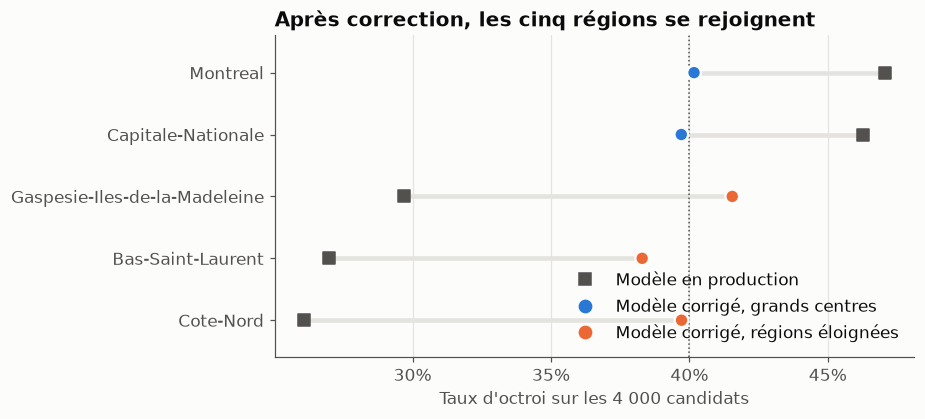

In [15]:
display(audit.subgroup_table(candidates, baseline, retained))
audit.fig_before_after(candidates, baseline, retained)

- Dans chaque sous-groupe, le taux des régions éloignées remonte. Les deux groupes se
  rejoignent selon la première génération, le revenu, le programme et la région.
- Le budget étant fixe, les grands centres reçoivent moins de bourses qu'avant : c'est le
  coût de la correction, et il est supporté surtout par les candidats à revenu élevé et
  à peu d'heures travaillées, que le comité favorisait.
- Un effet est voulu et doit être assumé : le modèle corrigé récompense les heures
  travaillées, donc les candidats qui travaillent beaucoup obtiennent davantage, dans les
  deux groupes. Les candidats qui travaillent peu, y compris en région éloignée, gagnent
  moins à la correction. À heures égales, les grands centres gardent un taux plus élevé :
  leur cote R est un peu plus haute.
- Ni la première génération ni le programme ne sont lus par le modèle ; leurs écarts
  résiduels reflètent les profils, pas un traitement différent.

## 8. Limites

- **Données synthétiques.** Le comité y suit une règle simple et stable ; un comité réel
  serait moins régulier, et la pénalité pourrait varier selon les dossiers.
- **Étalon inconnu.** L'égalité des chances est mesurée contre nos hypothèses sur le
  mérite, pas contre l'étalon du jury. Les retours du correcteur, obtenus sur un
  sous-ensemble, orientent le choix entre hypothèses mais ne le prouvent pas.
- **Les heures travaillées comme mérite.** Les retenir est un choix de valeur : elles
  peuvent traduire l'effort, mais aussi la contrainte financière. L'institution doit le
  valider.
- **Deux blocs.** Les régions d'un même bloc sont indiscernables dans ces données ; un
  écart entre régions d'un même bloc ne serait pas détecté ici, d'où le suivi par région
  prévu en production.
- **Une interaction non modélisée.** Le poids des heures diminue légèrement quand la cote
  R est élevée (`analysis/a10_hours_program.py`). L'effet est faible à la hauteur du
  seuil d'octroi et la règle retenue l'ignore.
- **Ce qui n'est pas dans les colonnes.** Si le mérite réel dépend d'éléments absents du
  fichier, aucun modèle construit sur ces colonnes ne peut le retrouver.

## 9. Comment le modèle corrigé a été trouvé

### De l'audit à la règle

La correction découle directement du diagnostic. Le comité se résume à quatre poids
(section 2) ; deux d'entre eux sont des biais (section 3). On réapprend les quatre poids
sur l'historique, région comprise, on retire les deux biais, et il reste une règle qui
se lit en une ligne.

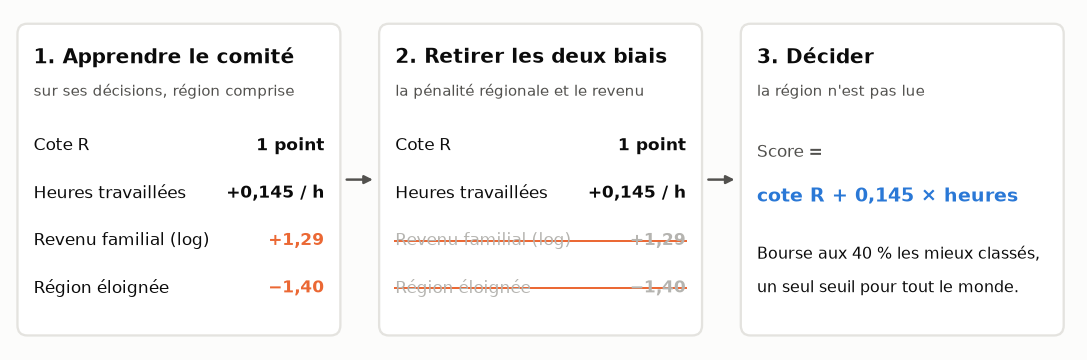

In [16]:
pitch.fig_method(history)

Apprendre **avec** la région est ce qui distingue cette méthode du réflexe « retirer la
colonne » : c'est la seule façon d'obtenir le vrai poids des heures (section 4).

### Vérifier sans voir l'étalon

L'étalon du jury est caché, et les décisions du comité ne peuvent pas servir de
référence. Nous avons procédé en trois temps.

1. **Des hypothèses.** Plusieurs définitions plausibles du mérite (section 6), et une
   règle de lecture : un modèle n'est jamais jugé sur l'hypothèse qu'il incarne, où il
   serait parfait par construction.
2. **Des familles de modèles.** Des règles simples, des règles qui favorisent le besoin,
   des modèles entraînés après avoir retiré, sous-pondéré ou réétiqueté les décisions
   que la pénalité a décidées, et les deux méthodes de fairlearn sous contrainte de
   parité. Chaque essai est une spécification rejouable (`experiments/`,
   `runs/ledger.csv`).
3. **Le correcteur comme arbitre entre familles.** Chaque fichier soumis est un modèle
   complet, dans le budget, que nous aurions accepté de garder. Le correcteur renvoie un
   accord avec l'étalon sur un sous-ensemble : il sert à départager les hypothèses et les
   familles, jamais à régler un paramètre.

,fichier,modèle,famille,accord avec l'étalon (%),F1 macro (%),écart de parité,la décision lit la région
02_r_plus_hours.csv,02,Cote R + heures travaillées (retenu),Règles simples,94.63,94.40,0.000,False
11_corrected_region_quotas.csv,11,"Comité corrigé, quotas par région",Modèles entraînés,94.63,94.40,-0.001,True
09_dropped_forest.csv,09,"Forêt, décisions biaisées retirées",Modèles entraînés,94.48,94.24,-0.006,False
08_relabelled_logit.csv,08,"Logit, décisions biaisées réétiquetées",Modèles entraînés,94.48,94.24,-0.013,False
14_r_plus_018_hours.csv,14,"Cote R + heures, poids plus fort",Règles simples,94.33,94.09,-0.021,False
07_weighted_logit.csv,07,"Logit, décisions biaisées sous-pondérées",Modèles entraînés,94.18,93.93,0.016,False
10_dropped_band_boosting.csv,10,"Boosting, décisions biaisées retirées",Modèles entraînés,93.93,93.67,0.007,False
16_r_plus_0059_hours.csv,16,"Cote R + heures, poids appris sans le groupe",Règles simples,93.78,93.51,0.045,False
03_r_within_group.csv,03,Cote R classée dans chaque groupe,Règles simples,92.68,92.37,0.000,True
04_committee_no_penalty.csv,04,"Comité sans la pénalité, revenu gardé",Règles simples,92.53,92.21,0.054,False


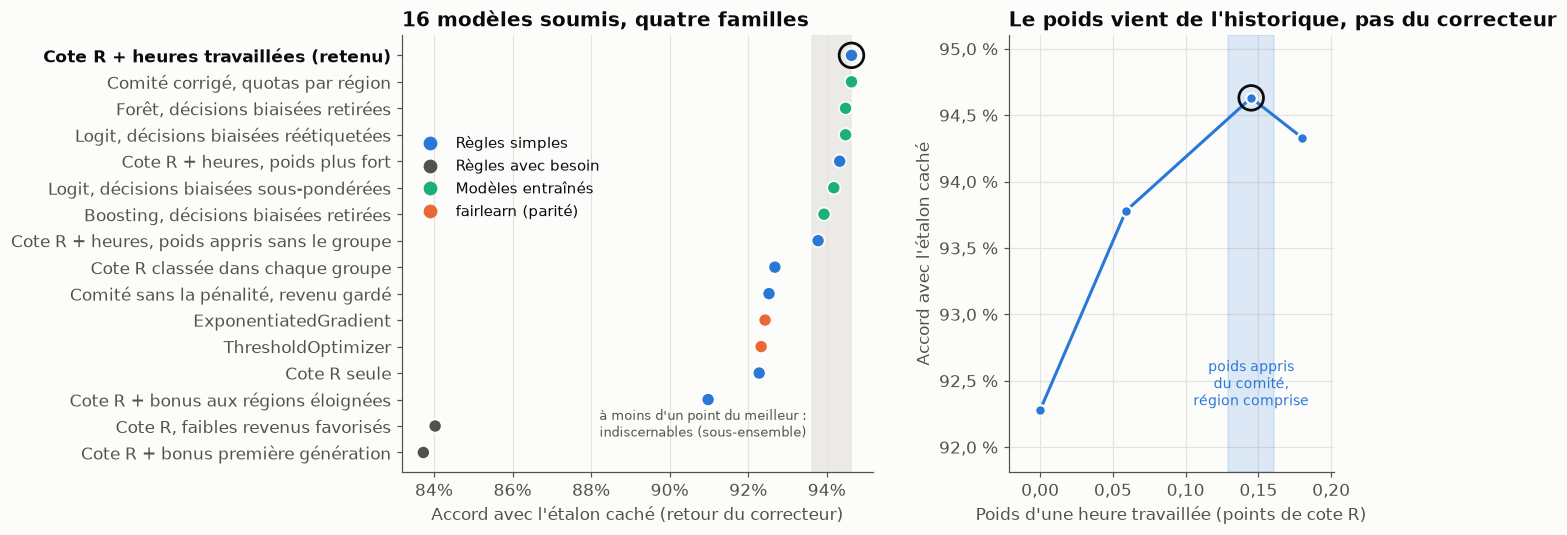

In [17]:
display(pitch.search_table())
pitch.fig_search()

Ce que disent ces retours.

- **La règle « cote R et heures travaillées » arrive en tête**, à égalité avec sa
  variante à quotas par région, qui prend presque les mêmes décisions.
- **Les modèles entraînés convergent vers elle sans la dépasser.** Forêt, boosting ou
  régression logistique, entraînés sur un historique nettoyé, retrouvent la même règle à
  quelques décisions près : il n'y a rien d'autre à apprendre dans ces données, parce
  que le comité est additif. À résultat égal, nous gardons la forme la plus simple.
- **Les règles qui favorisent le besoin sont loin derrière** : l'étalon ne récompense ni
  le faible revenu ni la première génération.
- **La parité imposée ne suffit pas.** Les deux méthodes de fairlearn égalisent les taux
  mais s'accordent moins bien avec l'étalon : elles choisissent d'autres candidats dans
  chaque groupe. Rendre aux régions éloignées la pénalité sous forme de bonus corrige
  trop.
- **Le poids des heures vient de l'historique.** Le poids appris du comité, région
  comprise, se trouve là où l'accord est le plus haut ; le poids appris sans la région
  fait moins bien. Nous n'avons pas déplacé ce poids pour gagner des décimales : un
  poids plus fort, essayé une fois, ne fait pas mieux.

Les écarts de moins d'un point entre les fichiers de tête ne sont pas significatifs
(sous-ensemble de taille inconnue). Ce que les retours établissent, c'est le classement
des familles, et il est net.

Une réserve : sous nos hypothèses, des règles intermédiaires entre « cote R seule » et
« cote R et heures » ont un pire cas estimé un peu meilleur, parce qu'elles se couvrent
contre l'hypothèse « cote R seule » (`python run.py --board`). Nous ne les retenons pas :
le correcteur place cette hypothèse derrière, le gain estimé est de l'ordre du bruit de
l'estimation, et une règle à deux régimes s'explique moins bien à un candidat.

## 10. Suite

**Correction.** `model_corrige.py` construit le modèle retenu, trace le compromis entre
équité et utilité quand on retire progressivement la pénalité (front de Pareto,
`figures/pareto.png`), le compare au modèle en production et aux deux méthodes de
fairlearn, puis écrit `predictions.csv` dans le budget.

**Gouvernance.** `gouvernance.md` fixe les choix assumés, les rôles, les indicateurs de
surveillance et les voies de recours ; `monitoring.py` en est le prototype exécutable.